# 实验七　影评情感识别
以 IMDb 长影评与 SST-2 短评为语料，比较 RNN、BiLSTM-Attention、Transformer Encoder 和微调的 BERT-Tiny。依次完成训练、域内评估、单因素消融、双向迁移和成对文本扰动。

In [1]:
from pathlib import Path
import sys, re, html, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix
root = (Path('exp7') if Path('exp7/resources.py').exists() else Path('.')).resolve()
sys.path.insert(0,str(root))
from resources import prepare, BERT, DATA
prepare()
out = root/'results'/'exp7A'; out.mkdir(parents=True, exist_ok=True)
cache = BERT.parent/'checkpoints'; cache.mkdir(exist_ok=True)
seed = 707; max_len = 96; device = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei','SimHei','DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
torch.set_num_threads(4)
print('训练设备', device, torch.cuda.get_device_name() if device=='cuda' else '')

训练设备 cuda NVIDIA GeForce RTX 5060


## 数据与切分
取两个训练集各 4,800 条，按标签分层，每类 2,400 条。IMDb 另从训练池分层抽取 600 条验证样本，从官方测试集取 2,000 条。SST-2 官方验证集有标签，将其分层均分为调参和最终评估两部分。先为评估样本预留完整文本，再去除训练池中的同文记录和冲突标签。英文转小写、清理 HTML 和连续空白，保留标点和否定词。两个语料都是英文影视评论，迁移比较主要涉及文本长度与采样方式。

[IMDb 数据](https://huggingface.co/datasets/stanfordnlp/imdb) · [SST-2 数据](https://huggingface.co/datasets/stanfordnlp/sst2) · [Google BERT-Tiny 权重](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2)

In [2]:
def clean(s):
    return ' '.join(re.sub(r'<[^>]+>', ' ',html.unescape(s)).lower().split())

def read_split(domain, split):
    f = pd.read_parquet(DATA/f'{domain}_{split}.parquet').rename(columns={'sentence':'text'})
    f['source_row'] = np.arange(len(f)); f['official_split'] = split
    f['text'] = f.text.map(clean)
    f = f[(f.text!='') & (f.groupby('text').label.transform('nunique')==1)]
    return f[['text','label','source_row','official_split']].drop_duplicates('text').reset_index(drop=True)

def balanced(f,n):
    return pd.concat([f[f.label==y].sample(n//2,random_state=seed) for y in [0,1]]).sample(frac=1,random_state=seed)

domains = ['imdb','sst2']; frames = {}
sst_val = read_split('sst2','validation')
frames['sst2','val'],frames['sst2','test'] = train_test_split(sst_val,test_size=0.5,random_state=seed,stratify=sst_val.label)
held = set(sst_val.text)
imdb_test = read_split('imdb','test')
frames['imdb','test'] = balanced(imdb_test[~imdb_test.text.isin(held)],2000)
held.update(frames['imdb','test'].text)
for domain in domains:
    pool = read_split(domain,'train'); pool = pool[~pool.text.isin(held)]
    if domain=='imdb':
        frames[domain,'val'] = balanced(pool,600); held.update(frames[domain,'val'].text)
        pool = pool[~pool.text.isin(held)]
    frames[domain,'train'] = balanced(pool,4800); held.update(frames[domain,'train'].text)
manifest = pd.concat([f.assign(domain=d,split=s) for (d,s),f in frames.items()],ignore_index=True)
assert manifest.text.is_unique
manifest.drop(columns='text').to_csv(out/'split_manifest.csv',index=False)
tokenizer = AutoTokenizer.from_pretrained(BERT)
def tokenize(texts):
    return torch.tensor(tokenizer(list(texts),truncation=True,max_length=max_len,padding='max_length')['input_ids'])
data = {}; descriptions=[]
for key, frame in frames.items():
    token_ids = tokenize(frame.text); labels = torch.tensor(frame.label.to_numpy(),dtype=torch.long)
    data[key] = TensorDataset(token_ids,labels)
    lengths = np.array([len(ids) for ids in tokenizer(frame.text.tolist(),truncation=False,verbose=False)['input_ids']])
    descriptions.append([*key,len(frame),int(labels.sum()),np.median(lengths),(lengths>max_len).mean()])
stats = pd.DataFrame(descriptions,columns=['domain','split','n','positive','median_tokens','truncated_fraction'])
stats.to_csv(out/'data_summary.csv',index=False); display(stats)

,domain,split,n,positive,median_tokens,truncated_fraction
0,sst2,val,436,222,24.0,0.000000
1,sst2,test,436,222,25.0,0.000000
2,imdb,test,2000,1000,216.0,0.928000
3,imdb,val,600,300,218.0,0.931667
4,imdb,train,4800,2400,218.0,0.926667
5,sst2,train,4800,2400,11.0,0.000000


## 模型与注意力
三个自建模型共用 WordPiece 词表和 128 维词向量。主实验用预训练词嵌入初始化，训练时允许更新。RNN 对有效位置做均值池化。双向 LSTM 用可学习的注意力权重汇总各位置。Transformer 加入可学习的位置编码，使用多头自注意力、前馈层和残差连接。BERT-Tiny 载入整个两层预训练编码器，以首位置表示做分类，全量微调。特殊标记在所有模型中采用相同的编码方式。

In [3]:
pretrained = AutoModel.from_pretrained(BERT).get_input_embeddings().weight.detach().clone()
class SentimentModel(nn.Module):
    def __init__(self, kind, hidden=64, heads=4, embedding='pretrained', position=True):
        super().__init__(); self.kind = kind; self.position = position
        self.drop = nn.Dropout(0.15)
        if kind=='BERT':
            self.bert = AutoModel.from_pretrained(BERT); width = self.bert.config.hidden_size
        else:
            self.emb = nn.Embedding(*pretrained.shape, padding_idx=0)
            if embedding=='pretrained': self.emb.weight.data.copy_(pretrained)
            if kind=='RNN':
                self.rnn = nn.RNN(128,hidden,batch_first=True); width=hidden
            elif kind=='BiLSTM':
                self.rnn = nn.LSTM(128,hidden,bidirectional=True,batch_first=True); width=hidden*2
                self.att = nn.Sequential(nn.Linear(width,hidden),nn.Tanh(),nn.Linear(hidden,1))
            else:
                width=128; self.pos=nn.Embedding(max_len,width)
                self.mha=nn.MultiheadAttention(width,heads,dropout=0.1,batch_first=True)
                self.norm1=nn.LayerNorm(width); self.norm2=nn.LayerNorm(width)
                self.ff=nn.Sequential(nn.Linear(width,256),nn.GELU(),self.drop,nn.Linear(256,width))
        self.fc=nn.Linear(width,2)

    def forward(self,ids,explain=False):
        valid=ids.ne(0); attention=None
        if self.kind=='BERT':
            pooled=self.bert(input_ids=ids,attention_mask=valid).last_hidden_state[:,0]
        else:
            x=self.emb(ids)
            if self.kind=='BiLSTM':
                packed=pack_padded_sequence(x,valid.sum(1).cpu(),batch_first=True,enforce_sorted=False)
                packed,_=self.rnn(packed)
                x,_=pad_packed_sequence(packed,batch_first=True,total_length=ids.shape[1])
                attention=self.att(x).squeeze(-1).masked_fill(~valid,-torch.inf).softmax(-1)
                pooled=(x*attention.unsqueeze(-1)).sum(1)
            else:
                if self.kind=='RNN': x,_=self.rnn(x)
                else:
                    if self.position: x=x+self.pos(torch.arange(ids.shape[1],device=ids.device))
                    update,attention=self.mha(x,x,x,key_padding_mask=~valid,need_weights=explain,average_attn_weights=False)
                    x=self.norm1(x+self.drop(update)); x=self.norm2(x+self.drop(self.ff(x)))
                pooled=(x*valid.unsqueeze(-1)).sum(1)/valid.sum(1,keepdim=True)
        logits=self.fc(self.drop(pooled))
        return (logits,attention) if explain else logits

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 训练与验证选模
每个配置独立训练 4 轮，批量大小 64，交叉熵损失和 AdamW 优化器。自建模型学习率 0.001，BERT 学习率 0.0002。按验证集宏 F1 选轮次，分数相同取较早一轮。所有预测都使用对应验证最优权重，固定种子并保留每轮损失和验证分数。

In [4]:
models=['RNN','BiLSTM','Transformer','BERT']; history=[]; configs={}
def batches(ds,train=False):
    return DataLoader(ds,batch_size=64,shuffle=train,generator=torch.Generator().manual_seed(seed) if train else None)
def trim(ids): return ids[:,:int(ids.ne(0).sum(1).max())].to(device)
@torch.inference_mode()
def probabilities(model,ds):
    model.eval()
    return torch.cat([model(trim(ids)).softmax(1)[:,1].cpu() for ids,_ in batches(ds)]).numpy()

def fit(domain,name,kind,**kwargs):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    net=SentimentModel(kind,**kwargs).to(device); configs[domain,name]=(kind,kwargs)
    lr=2e-4 if kind=='BERT' else 1e-3
    opt=torch.optim.AdamW(net.parameters(),lr=lr); best=-1
    train_loader=batches(data[domain,'train'],True)
    for epoch in range(1,5):
        net.train(); total=0
        for ids,y in train_loader:
            opt.zero_grad(); logits=net(trim(ids)); loss=nn.functional.cross_entropy(logits,y.to(device))
            loss.backward(); nn.utils.clip_grad_norm_(net.parameters(),1.0); opt.step(); total+=loss.item()*len(y)
        val=data[domain,'val']; p=probabilities(net,val); score=f1_score(val.tensors[1],p>0.5,average='macro')
        history.append([domain,name,epoch,total/len(train_loader.dataset),score])
        if score>best:
            best=score; torch.save(net.state_dict(),cache/f'{domain}_{name}.pt')
    pd.DataFrame(history,columns=['domain','name','epoch','train_loss','val_macro_f1']).to_csv(out/'training.csv',index=False)
    print(domain,name,round(best,4),flush=True)

def restore(domain,name):
    kind,kwargs=configs[domain,name]; net=SentimentModel(kind,**kwargs)
    net.load_state_dict(torch.load(cache/f'{domain}_{name}.pt',map_location='cpu',weights_only=True)); return net.to(device).eval()
for domain in domains:
    for name in models: fit(domain,name,name)

imdb RNN 0.7816


imdb BiLSTM 0.7779


imdb Transformer 0.774


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


imdb BERT 0.7925


... (2 outputs left out)

sst2 Transformer 0.7265


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


sst2 BERT 0.7552


## 两个数据集的域内分类与双向迁移
每个源域模型直接预测两个目标域，不做目标域更新。精确率、召回率和 F1 取两个类别的宏平均。混淆矩阵的行是真实类别，列是预测类别。逐条结果保留来源行号、真实标签、正面概率和预测类别。

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


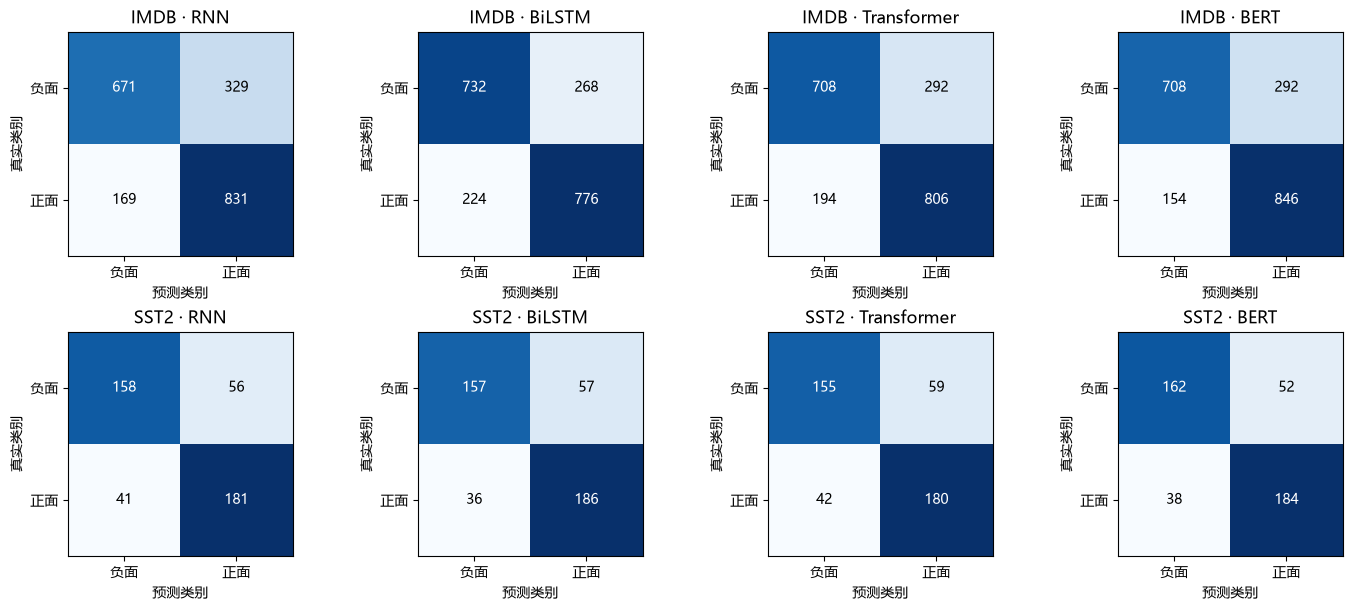

,train_domain,test_domain,model,accuracy,macro_precision,macro_recall,macro_f1
0,imdb,imdb,RNN,0.7510,0.7576,0.7510,0.7494
1,imdb,sst2,RNN,0.6995,0.6996,0.6991,0.6992
2,imdb,imdb,BiLSTM,0.7540,0.7545,0.7540,0.7539
3,imdb,sst2,BiLSTM,0.7294,0.7294,0.7290,0.7291
4,imdb,imdb,Transformer,0.7570,0.7595,0.7570,0.7564
5,imdb,sst2,Transformer,0.5849,0.6498,0.5907,0.5423
6,imdb,imdb,BERT,0.7770,0.7824,0.7770,0.7759
7,imdb,sst2,BERT,0.7018,0.7191,0.6991,0.6939
8,sst2,imdb,RNN,0.6880,0.7030,0.6880,0.6821
9,sst2,sst2,RNN,0.7775,0.7788,0.7768,0.7769


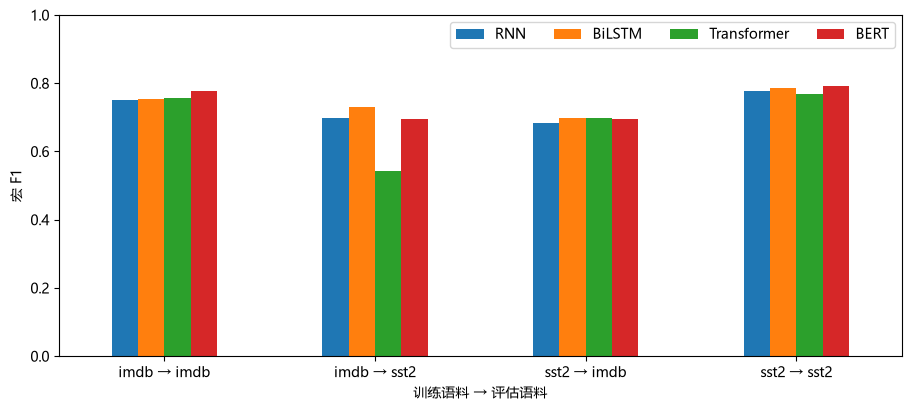

In [5]:
def metrics(y,p):
    pred=(p>0.5).astype(int); prec,rec,f1,_=precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    return [accuracy_score(y,pred),prec,rec,f1]
columns=['accuracy','macro_precision','macro_recall','macro_f1']; results=[]; outputs=[]
fig,axes=plt.subplots(2,4,figsize=(14,6),layout='constrained')
for i,source in enumerate(domains):
    for j,name in enumerate(models):
        net=restore(source,name)
        for target in domains:
            f=frames[target,'test']; prob=probabilities(net,data[target,'test']); pred=(prob>0.5).astype(int)
            results.append([source,target,name,*metrics(f.label,prob)])
            outputs.append(f[['source_row','label','text']].assign(train_domain=source,test_domain=target,model=name,positive_prob=prob,predicted=pred))
            if source==target:
                cm=confusion_matrix(f.label,pred,labels=[0,1]); ax=axes[i,j]; ax.imshow(cm,cmap='Blues')
                for a in range(2):
                    for b in range(2): ax.text(b,a,str(cm[a,b]),ha='center',va='center',color='white' if cm[a,b]>cm.max()*0.55 else 'black')
                ax.set(title=f'{source.upper()} · {name}',xticks=[0,1],yticks=[0,1],xticklabels=['负面','正面'],yticklabels=['负面','正面'],xlabel='预测类别',ylabel='真实类别')
fig.savefig(out/'confusion.png',dpi=150); plt.show()
report=pd.DataFrame(results,columns=['train_domain','test_domain','model',*columns]); report.to_csv(out/'metrics.csv',index=False)
predictions=pd.concat(outputs,ignore_index=True); predictions.drop(columns='text').to_csv(out/'predictions.csv',index=False)
errors=predictions.query('train_domain == test_domain and predicted != label').copy()
errors.groupby(['train_domain','model','label'],sort=False).head(2).to_csv(out/'error_examples.csv',index=False)
display(report.round(4))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained'); table=report.assign(pair=report.train_domain+' → '+report.test_domain).pivot(index='pair',columns='model',values='macro_f1'); table[models].plot.bar(ax=ax,rot=0); ax.set(ylabel='宏 F1',xlabel='训练语料 → 评估语料',ylim=(0,1)); ax.legend(ncol=4); fig.savefig(out/'transfer.png',dpi=160); plt.show()

## 单因素消融
在 SST-2 上复用主实验基线，每组仅改变一个因素。BiLSTM 隐藏宽度从每方向 64 改为 32，Transformer 依次比较 4 头和 2 头、预训练词嵌入和随机初始化、保留和关闭位置编码。嵌入在两种初始化下都参与训练。

sst2 hidden32 0.7415


sst2 heads2 0.7454


sst2 random_embed 0.6496


sst2 no_position 0.7387


,baseline,variant,change,baseline_f1,accuracy,macro_precision,macro_recall,macro_f1,delta_f1
0,BiLSTM,hidden32,隐藏维度 64 → 32,0.785749,0.800459,0.804629,0.799339,0.799309,0.013560
1,Transformer,heads2,注意力头数 4 → 2,0.767584,0.770642,0.770595,0.770481,0.770521,0.002937
2,Transformer,random_embed,预训练 → 随机嵌入,0.767584,0.669725,0.676249,0.667761,0.664959,-0.102625
3,Transformer,no_position,关闭位置编码,0.767584,0.786697,0.797872,0.788436,0.785314,0.017729


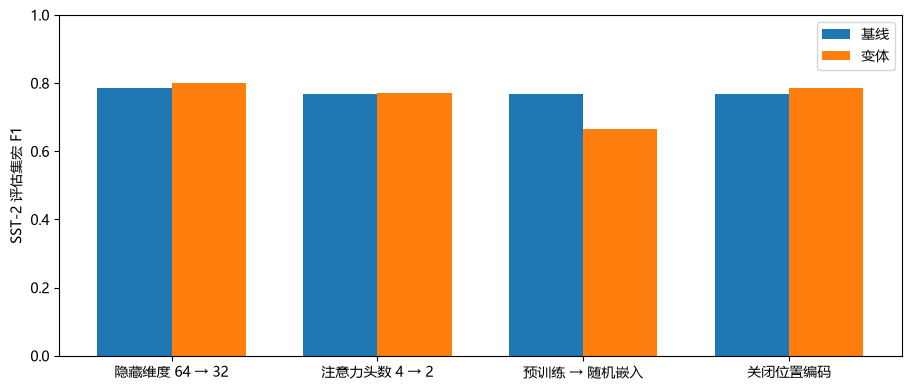

In [6]:
variants=[('BiLSTM','hidden32',{'hidden':32},'隐藏维度 64 → 32'),('Transformer','heads2',{'heads':2},'注意力头数 4 → 2'),('Transformer','random_embed',{'embedding':'random'},'预训练 → 随机嵌入'),('Transformer','no_position',{'position':False},'关闭位置编码')]; ab=[]
for kind,name,args,change in variants:
    fit('sst2',name,kind,**args); net=restore('sst2',name); prob=probabilities(net,data['sst2','test'])
    base=report.query("train_domain=='sst2' and test_domain=='sst2' and model==@kind").iloc[0]
    scores=metrics(frames['sst2','test'].label,prob); ab.append([kind,name,change,base.macro_f1,*scores,scores[-1]-base.macro_f1])
ablation=pd.DataFrame(ab,columns=['baseline','variant','change','baseline_f1',*columns,'delta_f1']); ablation.to_csv(out/'ablation.csv',index=False); display(ablation)
fig,ax=plt.subplots(figsize=(9,3.8),layout='constrained'); xx=np.arange(len(ab)); ax.bar(xx-0.18,ablation.baseline_f1,0.36,label='基线'); ax.bar(xx+0.18,ablation.macro_f1,0.36,label='变体'); ax.set(xticks=xx,xticklabels=ablation.change,ylim=(0,1),ylabel='SST-2 评估集宏 F1'); ax.legend(); fig.savefig(out/'ablation.png',dpi=160); plt.show()

## 成对文本扰动与注意力解释
构造 8 个正面和 8 个负面原句。对每个原句分别替换近义词、补入不改变观点的背景从句、显式加入 not。前两类预期保持标签，否定组按预先设定的相反倾向单独计分。记录原句和变体都预测正确的比例，以及原本预测正确时变体命中预期的比例。模板句子的用词和标签属于本实验的人工设定。

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: E:\CODE\Tutorial\DeepLearning-exp\.cache\exp7\bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


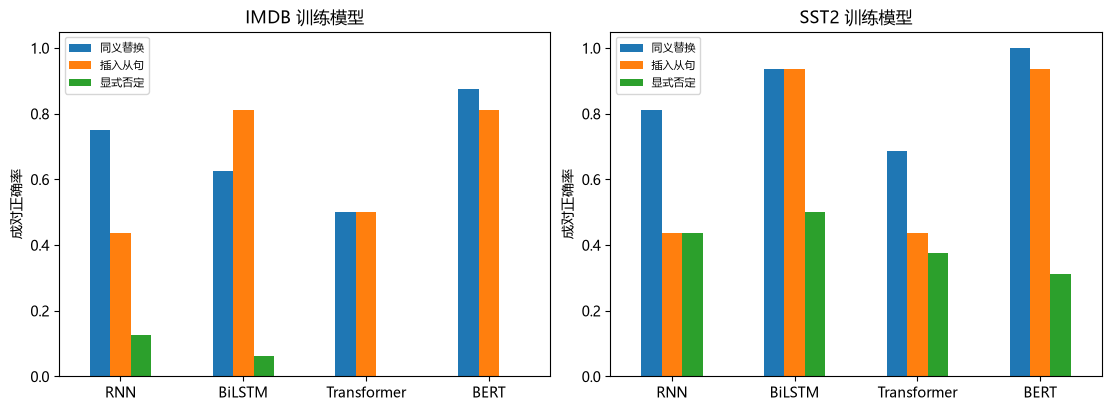

In [7]:
words=[('enjoyable','entertaining',1),('wonderful','excellent',1),('good','great',1),('funny','amusing',1),('moving','touching',1),('engaging','captivating',1),('delightful','charming',1),('impressive','remarkable',1),('boring','dull',0),('terrible','awful',0),('bad','poor',0),('tedious','tiresome',0),('disappointing','unsatisfying',0),('predictable','formulaic',0),('annoying','irritating',0),('unpleasant','disagreeable',0)]
probes=[]
for i,(word,syn,y) in enumerate(words):
    original=f'the film was {word}.'
    for change,variant,expected in [('同义替换',f'the film was {syn}.',y),('插入从句',f'the film, which i watched at home with my family last sunday, was {word}.',y),('显式否定',f'the film was not {word}.',1-y)]:
        probes.append([i,change,original,variant,y,expected])
pairs=pd.DataFrame(probes,columns=['id','change','original','variant','label','expected']); diagnostics=[]
for source in domains:
    for name in models:
        net=restore(source,name); f=pairs.copy()
        for col in ['original','variant']:
            ds=TensorDataset(tokenize(f[col]),torch.zeros(len(f))); p=probabilities(net,ds)
            f[col+'_p']=p; f[col+'_pred']=(p>0.5).astype(int)
        f['original_ok']=f.original_pred.eq(f.label); f['variant_ok']=f.variant_pred.eq(f.expected)
        f['both_ok']=f.original_ok & f.variant_ok; f['flipped']=f.variant_pred.ne(f.original_pred)
        diagnostics.append(f.assign(train_domain=source,model=name))
probe_results=pd.concat(diagnostics,ignore_index=True); probe_results.to_csv(out/'probe_predictions.csv',index=False)
rates=probe_results.groupby(['train_domain','model','change']).agg(n=('id','size'),original_correct=('original_ok','sum'),both_correct=('both_ok','sum'),pair_accuracy=('both_ok','mean'),flip_rate=('flipped','mean')).reset_index()
rates['conditional_accuracy']=rates.both_correct/rates.original_correct.replace(0,np.nan); rates.to_csv(out/'robustness.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,domain in zip(axes,domains):
    rates[rates.train_domain==domain].pivot(index='model',columns='change',values='pair_accuracy').reindex(models).plot.bar(ax=ax,rot=0); ax.set(title=domain.upper()+' 训练模型',ylim=(0,1.05),xlabel='',ylabel='成对正确率'); ax.legend(fontsize=8)
fig.savefig(out/'robustness.png',dpi=160); plt.show()

对固定否定句可视化 SST-2 模型的注意力。BiLSTM 给每个位置分配一个池化权重，Transformer 的每个注意力头按查询词逐行分配权重。热图包括特殊标记，仅显示输入实际使用的位置。各头采用相同的颜色范围。

BiLSTM P(正面)= 0.066
Transformer P(正面)= 0.226


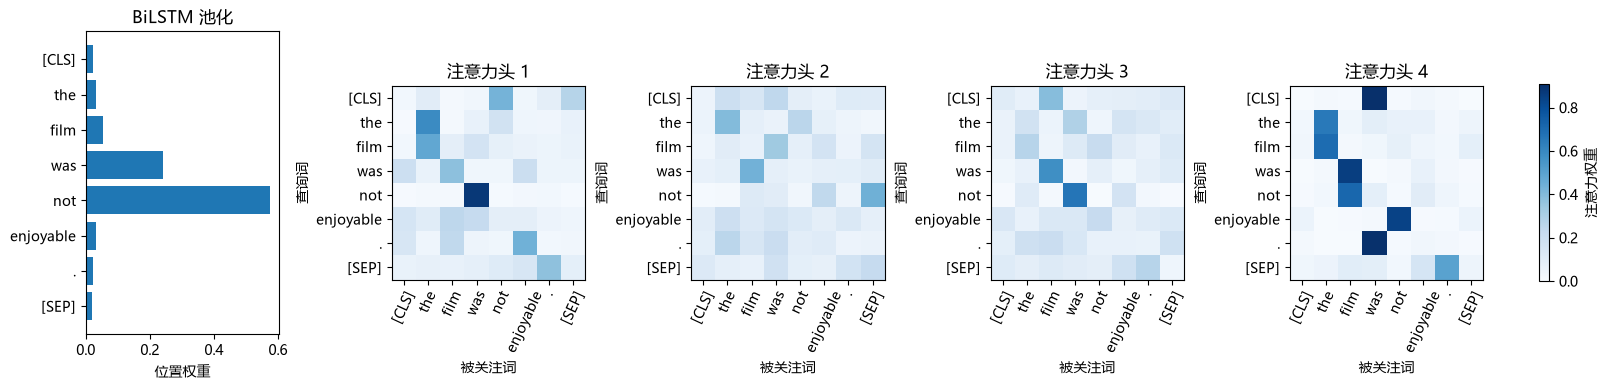

In [8]:
sentence='the film was not enjoyable.'; ids=trim(tokenize([sentence])); tokens=tokenizer.convert_ids_to_tokens(ids[0].tolist())
fig,axes=plt.subplots(1,5,figsize=(16,3.8),layout='constrained'); attrows=[]
for kind in ['BiLSTM','Transformer']:
    net=restore('sst2',kind)
    with torch.no_grad(): logits,att=net(ids,explain=True)
    print(kind,'P(正面)=',round(logits.softmax(1)[0,1].item(),3))
    if kind=='BiLSTM':
        arr=att[0].cpu().numpy(); axes[0].barh(tokens[::-1],arr[::-1]); axes[0].set(title='BiLSTM 池化',xlabel='位置权重')
        attrows.extend([kind,0,'pool',t,float(a)] for t,a in zip(tokens,arr))
    else:
        arr=att[0].cpu().numpy()
        for head,(a,ax) in enumerate(zip(arr,axes[1:]),1):
            im=ax.imshow(a,vmin=0,vmax=arr.max(),cmap='Blues'); ax.set(title=f'注意力头 {head}',xticks=range(len(tokens)),yticks=range(len(tokens)),xticklabels=tokens,yticklabels=tokens,xlabel='被关注词',ylabel='查询词'); ax.tick_params(axis='x',labelrotation=65)
            attrows.extend([kind,head,q,k,float(a[i,j])] for i,q in enumerate(tokens) for j,k in enumerate(tokens))
        fig.colorbar(im,ax=list(axes[1:]),shrink=0.65,label='注意力权重')
pd.DataFrame(attrows,columns=['model','head','query','key','weight']).to_csv(out/'attention.csv',index=False)
fig.savefig(out/'attention.png',dpi=160); plt.show()